# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [ ]:
# Runtime → Change runtime type → T4 GPU
from pathlib import Path
import os
import subprocess
import sys

if not Path("requirements-colab.txt").is_file():
    repo_dir = Path("/content/K4-Track-4-Day10-VisionLanguageModel")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "https://github.com/Tiendung3tzz/K4-Track-4-Day10-VisionLanguageModel.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
!nvidia-smi -L
!pip -q install -r requirements-colab.txt
# PEFT 0.21.2 không tương thích torchao 0.10 có sẵn; lab dùng bitsandbytes.
!pip -q uninstall -y torchao
!python -m pytest -q


GPU 0: Tesla T4 (UUID: GPU-a3be081f-137f-0db8-daa1-978c17c53a86)


..........................

.s.........................................    [100%]
68 passed, 1 skipped in 0.39s


In [ ]:
# Kaggle: dùng Colab Secrets. Không ghi khoá vào notebook.
import os
from google.colab import userdata

try:
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except userdata.SecretNotFoundError:
    print("Chưa có Kaggle Secrets; dùng URL zip công khai ở cell dữ liệu.")


## 1. Dữ liệu: tải và chia split

In [ ]:
from pathlib import Path
import os
import subprocess
import sys

if Path("work/raw").is_dir() and any(Path("work/raw").iterdir()):
    source = ["--source", "work/raw"]
elif os.environ.get("KAGGLE_KEY"):
    source = ["--kaggle"]
else:
    source = ["--zip", "https://www.kaggle.com/api/v1/datasets/download/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes"]
subprocess.run([sys.executable, "scripts/prepare_data.py", *source], check=True)


CompletedProcess(args=['/usr/bin/python3', 'scripts/prepare_data.py', '--zip', 'https://www.kaggle.com/api/v1/datasets/download/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes'], returncode=0)

dataset_version: d10-21e4070301
train images = 1422 boxes = {'manhole': 691, 'pothole': 1074, 'crack': 1750}
val images = 276 boxes = {'crack': 470, 'manhole': 103, 'pothole': 66}
test images = 311 boxes = {'crack': 299, 'manhole': 163, 'pothole': 121}


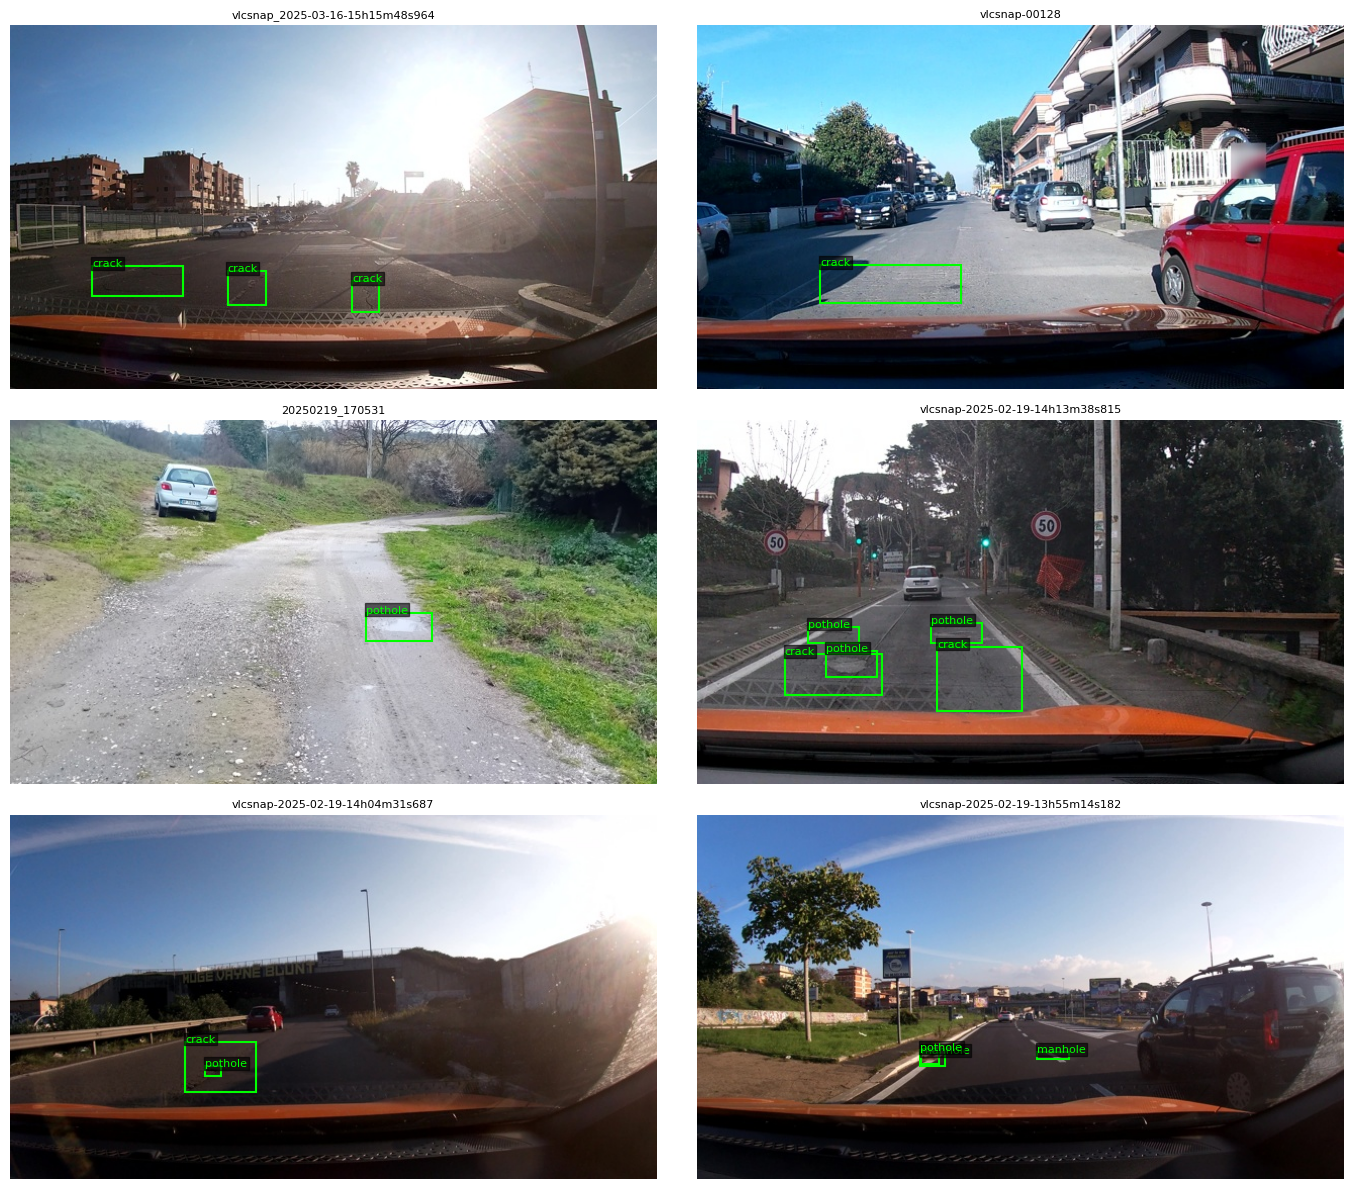

In [ ]:
import json
import math
import random
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scripts.labcommon import CLASSES, read_jsonl

DATA_DIR = Path("data")
WORK_DIR = Path("work")
WORK_DIR.mkdir(exist_ok=True)
splits = {
    name: read_jsonl(DATA_DIR / "splits" / f"{name}.jsonl")
    for name in ("train", "val", "test")
}
dataset_meta = json.loads((DATA_DIR / "splits/meta.json").read_text(encoding="utf-8"))
print("dataset_version:", dataset_meta["dataset_version"])

sessions = {name: {row["session"] for row in rows} for name, rows in splits.items()}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert sessions[a].isdisjoint(sessions[b]), f"Session giao nhau: {a}, {b}"

for name, rows in splits.items():
    counts = Counter(obj["label"] for row in rows for obj in row["objects"])
    assert len({row["image_id"] for row in rows}) == len(rows)
    assert dataset_meta["counts"][name] == {
        "images": len(rows), "boxes": {label: counts[label] for label in CLASSES}
    }
    print(name, "images =", len(rows), "boxes =", dict(counts))

def open_image(entry):
    with Image.open(DATA_DIR / entry["image_path"]) as source:
        image = source.convert("RGB")
    assert image.size == (entry["width"], entry["height"])
    return image

samples = random.Random(42).sample(splits["train"], 6)
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, entry in zip(axes.flat, samples):
    ax.imshow(open_image(entry))
    for obj in entry["objects"]:
        xc, yc, w, h = obj["yolo"]
        x1, y1 = (xc - w/2)*entry["width"], (yc - h/2)*entry["height"]
        ax.add_patch(Rectangle((x1, y1), w*entry["width"], h*entry["height"],
                               fill=False, edgecolor="lime", linewidth=1.5))
        ax.text(x1, y1, obj["label"], color="lime", fontsize=8,
                bbox={"facecolor": "black", "alpha": 0.6, "pad": 1})
    ax.set_title(entry["image_id"], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

train box có chiều rộng/cao bằng 0: 1
val box có chiều rộng/cao bằng 0: 0
test box có chiều rộng/cao bằng 0: 0
Sai số quy ngược pixel lớn nhất: 0.32


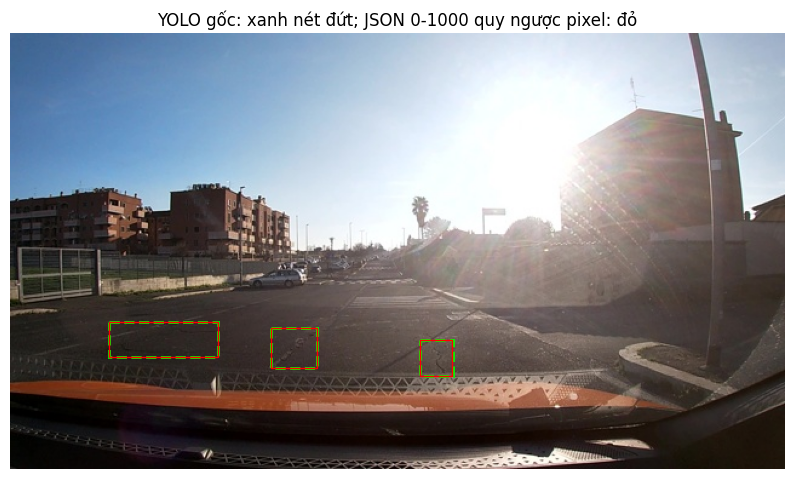

In [ ]:
def yolo_to_box(label, yolo):
    xc, yc, w, h = yolo
    coords = [(xc-w/2)*1000, (yc-h/2)*1000,
              (xc+w/2)*1000, (yc+h/2)*1000]
    return {"label": label,
            "bbox_2d": [max(0, min(1000, int(round(v)))) for v in coords]}

def objects_to_answer(objects):
    boxes = [yolo_to_box(obj["label"], obj["yolo"]) for obj in objects]
    # Dataset có một box train với h=0: loại khỏi đáp án SFT để JSON hợp lệ.
    # Không thay dữ liệu gốc hoặc ground truth của công cụ chấm.
    boxes = [box for box in boxes
             if box["bbox_2d"][2] > box["bbox_2d"][0]
             and box["bbox_2d"][3] > box["bbox_2d"][1]]
    boxes.sort(key=lambda box: (box["bbox_2d"][1], box["bbox_2d"][0]))
    return json.dumps(boxes, ensure_ascii=False, separators=(",", ":"))

PROMPT = (
    "Locate all road damage in this dashcam image. Allowed labels: pothole, crack, manhole. "
    "Return ONLY a JSON list with one object per region, using the keys label and bbox_2d. "
    "bbox_2d is [x1,y1,x2,y2], the top-left and bottom-right corners. "
    "Use integer coordinates normalized to 0-1000 independently along image width and height. "
    "Sort regions from top to bottom then left to right. If no damage is visible, return []."
)

assert yolo_to_box("pothole", [0.5, 0.5, 0.2, 0.2])["bbox_2d"] == [400, 400, 600, 600]
assert objects_to_answer([]) == "[]"
for name, rows in splits.items():
    invalid = sum(
        obj["yolo"][2] == 0 or obj["yolo"][3] == 0
        for row in rows for obj in row["objects"]
    )
    print(name, "box có chiều rộng/cao bằng 0:", invalid)

max_pixel_error = 0.0
for rows in splits.values():
    for row in rows:
        for obj in row["objects"]:
            xc, yc, w, h = obj["yolo"]
            expected = [(xc-w/2)*row["width"], (yc-h/2)*row["height"],
                        (xc+w/2)*row["width"], (yc+h/2)*row["height"]]
            box = yolo_to_box(obj["label"], obj["yolo"])["bbox_2d"]
            for value, target, extent in zip(box, expected,
                                             [row["width"],row["height"]]*2):
                error = abs(value*extent/1000-max(0,min(extent,target)))
                assert error <= extent/2000+1e-6
                max_pixel_error = max(max_pixel_error,error)
print("Sai số quy ngược pixel lớn nhất:", round(max_pixel_error, 6))

entry = samples[0]
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(open_image(entry))
for obj in entry["objects"]:
    xc, yc, w, h = obj["yolo"]
    ax.add_patch(Rectangle(((xc-w/2)*entry["width"],(yc-h/2)*entry["height"]),
                           w*entry["width"],h*entry["height"],fill=False,
                           edgecolor="lime",linestyle="--",linewidth=2))
for box in json.loads(objects_to_answer(entry["objects"])):
    x1, y1, x2, y2 = box["bbox_2d"]
    x1, x2 = x1*entry["width"]/1000, x2*entry["width"]/1000
    y1, y2 = y1*entry["height"]/1000, y2*entry["height"]/1000
    ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="red"))
ax.set_title("YOLO gốc: xanh nét đứt; JSON 0-1000 quy ngược pixel: đỏ")
ax.axis("off")
plt.show()

## 3. E0: zero-shot

In [ ]:
import gc
import time
import torch
from transformers import AutoProcessor, BitsAndBytesConfig, Qwen3VLForConditionalGeneration

MODEL_ID = "Qwen/Qwen3-VL-4B-Instruct"
processor = AutoProcessor.from_pretrained(MODEL_ID, token=False)
processor.tokenizer.padding_side = "left"
if processor.tokenizer.pad_token_id is None:
    processor.tokenizer.pad_token = processor.tokenizer.eos_token

def load_base_model():
    if not torch.cuda.is_available():
        raise RuntimeError("Chọn T4 GPU trong Colab trước khi chạy model.")
    quantization = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True,
        # Transformers 5.19 kiểm tra tên đầy đủ của cây module.
        llm_int8_skip_modules=["visual", "model.visual", "lm_head"],
    )
    model = Qwen3VLForConditionalGeneration.from_pretrained(
        MODEL_ID, token=False, quantization_config=quantization,
        dtype=torch.float16, device_map={"": 0}, attn_implementation="sdpa",
    )
    assert not any(
        type(module).__name__ == "Linear4bit" and ("visual" in name or name == "lm_head")
        for name, module in model.named_modules()
    ), "ViT/projector/lm_head phải được bỏ qua lượng tử hoá."
    return model

def user_message(image, prompt=PROMPT):
    return {"role": "user", "content": [
        {"type": "image", "image": image},
        {"type": "text", "text": prompt},
    ]}

def predict(model, entries, output_path, batch_size=4):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    model.eval()
    model.config.use_cache = True
    processor.tokenizer.padding_side = "left"
    with output_path.open("w", encoding="utf-8") as output:
        for start in range(0, len(entries), batch_size):
            batch = entries[start:start+batch_size]
            images = [open_image(row) for row in batch]
            chats = [[user_message(image)] for image in images]
            try:
                inputs = processor.apply_chat_template(
                    chats, tokenize=True, add_generation_prompt=True,
                    return_dict=True, return_tensors="pt",
                    processor_kwargs={"padding": True, "return_mm_token_type_ids": True},
                ).to(model.device)
                with torch.inference_mode(), torch.autocast("cuda", dtype=torch.float16):
                    generated = model.generate(**inputs, max_new_tokens=256, do_sample=False)
                raw = processor.batch_decode(
                    generated[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True
                )
                for row, text in zip(batch, raw):
                    output.write(json.dumps(
                        {"image_id": row["image_id"], "raw": text}, ensure_ascii=False
                    ) + "\n")
                output.flush()
                del inputs, generated
            finally:
                for image in images:
                    image.close()
            if start % 40 == 0:
                print(f"{output_path.name}: {min(start+batch_size, len(entries))}/{len(entries)}")
    return output_path

model = load_base_model()
torch.cuda.reset_peak_memory_stats()
e0_start = time.perf_counter()
try:
    predict(model, splits["test"], WORK_DIR / "e0.jsonl")
    torch.cuda.synchronize()
    e0_run = {"trainable_params": 0,
              "peak_vram_gb": torch.cuda.max_memory_allocated()/2**30,
              "train_minutes": (time.perf_counter()-e0_start)/60}
    print("E0 metadata (phút suy luận):", e0_run)
finally:
    del model
    gc.collect()
    torch.cuda.empty_cache()

for row in read_jsonl(WORK_DIR / "e0.jsonl")[:5]:
    print(row["image_id"], "->", row["raw"])

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


e0.jsonl: 4/311


...

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


E0 metadata (phút suy luận): {'trainable_params': 0, 'peak_vram_gb': 3.7785072326660156, 'train_minutes': 10.307935675200001}


vlcsnap-00200 -> [{"label":"manhole","bbox_2d":[759, 634, 845, 687]}]
vlcsnap-00201 -> []
vlcsnap-00202 -> [{"label":"manhole","bbox_2d":[297, 678, 399, 719]}]
vlcsnap-00203 -> [{"label":"crack","bbox_2d":[0, 457, 1000, 999]}]
vlcsnap-00204 -> [{"label":"manhole","bbox_2d":[253, 619, 325, 657]}]


In [ ]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

E0 [test] n=311 valid=0.965 P=0.134 R=0.081 F1=0.101 CI95=0.074-0.129 meanIoU=0.607 FP/img=0.98
   pothole  P=0.234 R=0.091 F1=0.131
   crack    P=0.032 R=0.023 F1=0.027
   manhole  P=0.330 R=0.178 F1=0.231


## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [ ]:
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

def encode_example(image, prompt, answer):
    user = user_message(image, prompt)
    kwargs = dict(tokenize=True, return_dict=True, return_tensors="pt",
                  processor_kwargs={"padding": False, "return_mm_token_type_ids": True})
    prompt_enc = processor.apply_chat_template(
        [user], add_generation_prompt=True, **kwargs
    )
    full_enc = processor.apply_chat_template(
        [user, {"role": "assistant", "content": [{"type": "text", "text": answer}]}],
        add_generation_prompt=False, **kwargs
    )
    n = prompt_enc["input_ids"].shape[1]
    assert torch.equal(
        full_enc["input_ids"][0, :n], prompt_enc["input_ids"][0]
    ), "Prompt phải là tiền tố của hội thoại đầy đủ."
    labels = full_enc["input_ids"].clone()
    labels[:, :n] = -100
    labels[full_enc["attention_mask"] == 0] = -100
    assert (labels != -100).any()
    full_enc["labels"] = labels
    return dict(full_enc)

def collate(batch):
    sequence_keys = {"input_ids", "attention_mask", "mm_token_type_ids", "labels"}
    image_keys = {"pixel_values", "image_grid_thw"}
    keys = set(batch[0])
    assert all(set(item) == keys for item in batch)
    assert keys <= sequence_keys | image_keys
    result = {}
    for key in keys:
        values = [item[key] for item in batch]
        if key in sequence_keys:
            padding = (
                processor.tokenizer.pad_token_id if key == "input_ids"
                else -100 if key == "labels" else 0
            )
            result[key] = pad_sequence(
                [value.squeeze(0) for value in values],
                batch_first=True, padding_value=padding,
            )
        else:
            result[key] = torch.cat(values, dim=0)
    assert torch.all(result["labels"][result["attention_mask"] == 0] == -100)
    return result

class RoadDataset(Dataset):
    def __init__(self, entries):
        self.entries = entries
    def __len__(self):
        return len(self.entries)
    def __getitem__(self, index):
        entry = self.entries[index]
        with open_image(entry) as image:
            return encode_example(image, PROMPT, objects_to_answer(entry["objects"]))

processor.tokenizer.padding_side = "right"
sample = RoadDataset(splits["train"])[0]
image_token_id = processor.tokenizer.convert_tokens_to_ids("<|image_pad|>")
image_tokens = int((sample["input_ids"] == image_token_id).sum())
assert image_tokens == 220, f"Phải có 220 token ảnh, nhận {image_tokens}"
assert torch.all(sample["labels"][sample["input_ids"] == image_token_id] == -100)
answer_ids = sample["labels"][sample["labels"] != -100]
decoded = processor.tokenizer.decode(answer_ids, skip_special_tokens=False)
assert "<|im_end|>" in decoded
assert json.loads(processor.tokenizer.decode(answer_ids, skip_special_tokens=True)) == json.loads(
    objects_to_answer(splits["train"][0]["objects"])
)
print("Vision tokens:", image_tokens)
print("Token được tính loss:", decoded)
del sample
# Hai ví dụ có độ dài đáp án khác nhau: pad chuỗi, nối các tensor ảnh.
examples = [RoadDataset(splits["train"])[i] for i in (0, 1)]
check_batch = collate(examples)
assert check_batch["pixel_values"].shape[0] == sum(e["pixel_values"].shape[0] for e in examples)
assert check_batch["image_grid_thw"].shape[0] == 2
assert torch.all(check_batch["labels"][check_batch["input_ids"] == image_token_id] == -100)
print("Collate batch 2:", {k: tuple(v.shape) for k, v in check_batch.items()})
del examples, check_batch


Vision tokens: 220
Token được tính loss: [{"label":"crack","bbox_2d":[430,467,583,506]},{"label":"pothole","bbox_2d":[361,475,414,522]},{"label":"manhole","bbox_2d":[317,481,616,625]},{"label":"pothole","bbox_2d":[583,500,627,614]},{"label":"crack","bbox_2d":[580,508,655,614]},{"label":"pothole","bbox_2d":[259,517,311,572]},{"label":"crack","bbox_2d":[397,628,447,717]},{"label":"crack","bbox_2d":[339,683,398,808]},{"label":"crack","bbox_2d":[158,789,361,994]}]<|im_end|>

Collate batch 2: {'image_grid_thw': (2, 3), 'mm_token_type_ids': (2, 585), 'pixel_values': (1760, 1536), 'input_ids': (2, 585), 'attention_mask': (2, 585), 'labels': (2, 585)}


## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
import re
import yaml
from peft import LoraConfig, PeftModel, TaskType, get_peft_model

LLM_TARGET = r"model\.language_model\.layers\.\d+\.(?:self_attn\.(?:q|k|v|o)_proj|mlp\.(?:gate|up|down)_proj)"
VIT_TARGET = r"model\.visual\.blocks\.\d+\.(?:attn\.(?:qkv|proj)|mlp\.(?:linear_fc1|linear_fc2))"

def read_config(key):
    return yaml.safe_load((Path("configs") / f"{key}.yaml").read_text(encoding="utf-8"))

def get_visual(model):
    base = model.get_base_model() if hasattr(model, "get_base_model") else model
    return base.model.visual

def apply_setup(model, setup):
    include_vit = setup["lora"]["targets"] == "llm+vit"
    targets = f"(?:{LLM_TARGET}|{VIT_TARGET})" if include_vit else LLM_TARGET
    matched = [name for name, _ in model.named_modules() if re.fullmatch(targets, name)]
    assert len(matched) == (348 if include_vit else 252), len(matched)
    for parameter in model.parameters():
        parameter.requires_grad_(False)
    model.enable_input_require_grads()
    lora = setup["lora"]
    model = get_peft_model(model, LoraConfig(
        r=int(lora["r"]), lora_alpha=int(lora["alpha"]),
        lora_dropout=float(lora["dropout"]), target_modules=targets,
        bias="none", task_type=TaskType.CAUSAL_LM,
    ))
    if setup["train_projector"]:
        visual = get_visual(model)
        for module in (visual.merger, visual.deepstack_merger_list):
            module.to(dtype=torch.float32)
            module.requires_grad_(True)
    # GradScaler cần gradient fp32; chỉ cast tham số có gradient, giữ nền NF4/fp16.
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            assert "lora_" in name or (
                setup["train_projector"] and
                ("visual.merger." in name or "visual.deepstack_merger_list." in name)
            ), name
            parameter.data = parameter.data.to(torch.float32)
    model.print_trainable_parameters()
    print("Số module LoRA:", len(matched))
    return model
# Đếm từng khối bằng cây kiến trúc thật, không đếm storage NF4 đã đóng gói.
from transformers import AutoConfig
with torch.device("meta"):
    architecture = Qwen3VLForConditionalGeneration._from_config(
        AutoConfig.from_pretrained(MODEL_ID, token=False)
    )
visual = architecture.model.visual
architecture_counts = {
    "total": sum(p.numel() for p in architecture.parameters()),
    "llm_with_embedding": sum(p.numel() for p in architecture.model.language_model.parameters()),
    "visual_total": sum(p.numel() for p in visual.parameters()),
    "merger": sum(p.numel() for p in visual.merger.parameters()),
    "deepstack_merger_list": sum(p.numel() for p in visual.deepstack_merger_list.parameters()),
}
architecture_counts["vit_without_projector"] = (
    architecture_counts["visual_total"] - architecture_counts["merger"]
    - architecture_counts["deepstack_merger_list"]
)
print("Tham số kiến trúc:", architecture_counts)
del architecture, visual

setup_checks = {}
for key in ("e1", "e2", "e3"):
    config = read_config(key)
    checked_model = apply_setup(load_base_model(), config)
    visual = get_visual(checked_model)
    projector = [p for module in (visual.merger, visual.deepstack_merger_list)
                 for p in module.parameters()]
    assert all(p.requires_grad == config["train_projector"] for p in projector)
    if config["train_projector"]:
        assert all(p.dtype == torch.float32 for p in projector)
    setup_checks[key] = sum(p.numel() for p in checked_model.parameters() if p.requires_grad)
    print(key.upper(), "trainable_params =", setup_checks[key])
    del checked_model, visual, projector
    gc.collect()
    torch.cuda.empty_cache()
assert setup_checks["e2"] - setup_checks["e1"] == (
    architecture_counts["merger"] + architecture_counts["deepstack_merger_list"]
)


Tham số kiến trúc: {'total': 4437815808, 'llm_with_embedding': 4022468096, 'visual_total': 415347712, 'merger': 27271680, 'deepstack_merger_list': 81833472, 'vit_without_projector': 306242560}


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

trainable params: 33,030,144 || all params: 4,470,845,952 || trainable%: 0.7388
Số module LoRA: 252
E1 trainable_params = 33030144


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

trainable params: 142,135,296 || all params: 4,470,845,952 || trainable%: 3.1792
Số module LoRA: 252
E2 trainable_params = 142135296


Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

trainable params: 148,426,752 || all params: 4,477,137,408 || trainable%: 3.3152
Số module LoRA: 348
E3 trainable_params = 148426752


## 6. Vòng huấn luyện

In [ ]:
# YOUR CODE HERE: vòng train, lưu adapter + run.json (GUIDE bước 6)

## 7. Suy luận và chấm E1–E3

In [ ]:
# YOUR CODE HERE: suy luận test → work/eN.jsonl rồi chạy scripts/score.py với --meta (GUIDE bước 7)

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# YOUR CODE HERE: GUIDE bước 8 và 9